<div style="text-align: center; margin-bottom: 25px;">
    <div style="margin-bottom: 20px;">
        <img src="https://upload.wikimedia.org/wikipedia/fr/5/5f/Safran_-_logo_2016.png" style="height: 60px; width: auto; vertical-align: middle; margin: 0 20px;">
    </div>
    <div style="background-color: #f0f0f0; padding: 15px 25px; border-radius: 12px; width: 60%; margin: auto;">
        <h1 style="margin: 0; font-family: Georgia, serif; color: #000000;">Implémentation de DeepTurbo</h1>
    </div>
</div>

## **1. Importation des modules**

In [59]:
from time import *

import datetime
import math as m
import numpy as np
import numpy.random as rd
import matplotlib.pyplot as plt

import turbocode as tc
import turbodecode as td

import deepturbo

from keras import models

## **2. Récupération du modèle**

In [60]:
network = models.load_model("deepmap.keras")

network.summary ()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 1784, 200)      │        63,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1784, 32)       │        32,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1784, 32)       │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 1784, 1)        │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 288,365 (1.10 MB)

 Trainable params: 96,121 (375.47 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 192,244 (750.96 KB)

## **3. Définitions des paramètres**

In [61]:
B = 2000
trame = 1784
Eb = 1  
Code_Rate = 1/3  
Ec = Eb*Code_Rate
snr11 = np.linspace (0, 11, 12)
t = [0.5 * m.erfc (np.sqrt (10**(k/10))) for k in snr11]
MaxLogMap = [0.086916, 0.043561, 0.016764, 0.005205, 0.001063, 0.0001617, 1.677e-05, 9.75e-07]
turboabs757 = [0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6]
turbocode757 = [0.00369, 0.0007167, 0.0002282, 8.70e-05, 2.37e-05, 1.32e-05, 5.46e-06, 2.98e-06, 1.280e-06]
turbomod18abs = [0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6]
turbomod18ord = [0.0010, 0.00024, 0.00010, 3.09e-05, 1.12e-05, 7.39e-06, 4.71e-06, 2.69e-06, 1.3e-06]
turboabs = [0.8, 0.9, 1, 1.2, 1.4, 1.6]
turbo = [0 for k in range (6)]

## **4. Monte Carlo**

In [62]:
for i in range(len(turboabs)):
    nombre_erreur = 0
    nombre_trame  = 0

    N0 = 10 ** (-turboabs[i] / 10)
    Lc = 4 / (3 * N0)

    while nombre_erreur < 2000 and nombre_trame < 10000:

        u = rd.randint(0, 2, (B, 1784))
        m = np.array([tc.turbo(u[b]) for b in range(B)])
        x = -2*m + 1
        n = rd.randn(B, 1784, 3) * np.sqrt(N0/2)
        y = x * np.sqrt(Ec) + n

        pred = deepturbo.decode(y, 10, network, Lc)  # (B, 1784)

        nombre_erreur += np.sum(u != (pred < 0).astype(int))
        nombre_trame  += B

        print(f"Étape {i} : erreurs : {nombre_erreur}, nombre trame : {nombre_trame}, BER : {nombre_erreur/(nombre_trame * 1784)}")

    print(f"Étape {i} : erreurs : {nombre_erreur}, nombre trame : {nombre_trame}, BER : {nombre_erreur/(nombre_trame * 1784)}")
    turbo[i] = nombre_erreur / (nombre_trame * 1784)

Étape 0 : erreurs : 4089, nombre trame : 2000, BER : 0.0011460201793721974
Étape 0 : erreurs : 4089, nombre trame : 2000, BER : 0.0011460201793721974
Étape 1 : erreurs : 1099, nombre trame : 2000, BER : 0.00030801569506726457
Étape 1 : erreurs : 1975, nombre trame : 4000, BER : 0.0002767656950672646
Étape 1 : erreurs : 2695, nombre trame : 6000, BER : 0.00025177503736920775
Étape 1 : erreurs : 2695, nombre trame : 6000, BER : 0.00025177503736920775
Étape 2 : erreurs : 390, nombre trame : 2000, BER : 0.00010930493273542601
Étape 2 : erreurs : 622, nombre trame : 4000, BER : 8.716367713004484e-05
Étape 2 : erreurs : 889, nombre trame : 6000, BER : 8.305306427503737e-05
Étape 2 : erreurs : 1181, nombre trame : 8000, BER : 8.27494394618834e-05
Étape 2 : erreurs : 1537, nombre trame : 10000, BER : 8.615470852017938e-05
Étape 2 : erreurs : 1537, nombre trame : 10000, BER : 8.615470852017938e-05
Étape 3 : erreurs : 85, nombre trame : 2000, BER : 2.382286995515695e-05
Étape 3 : erreurs : 180, 

## **5. Visualisation des performances**

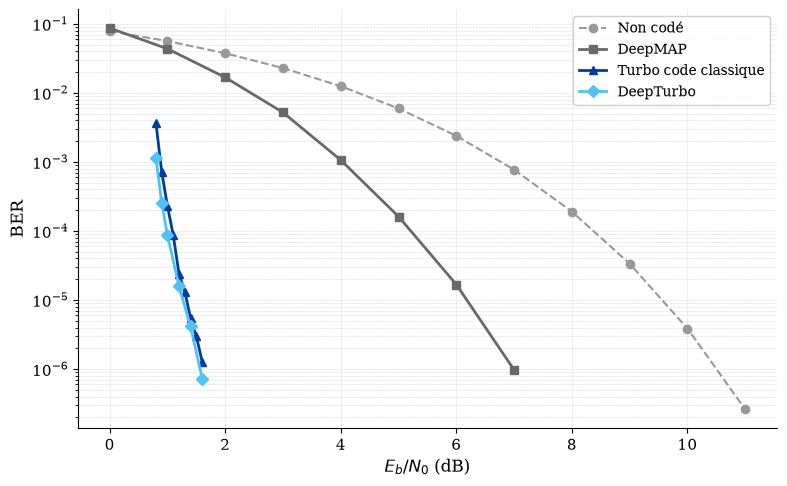

In [66]:
plt.rcParams.update({'font.family': 'serif', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,})

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(snr11, t, color='#999999', marker='o', markersize=6, linestyle='--', linewidth=1.5, label='Non codé')
ax.plot(snr11[:8], MaxLogMap, color='dimgrey', marker='s', markersize=6, linestyle='-', linewidth=2, label='DeepMAP')
ax.plot(turboabs757, turbocode757, color='#003B9F', marker='^', markersize=6, linestyle='-', linewidth=2, label='Turbo code classique')
ax.plot(turboabs, turbo, color='#4FC3F7', marker='D', markersize=6, linestyle='-', linewidth=2, label='DeepTurbo')

ax.set_yscale('log')
ax.set_xlabel('$E_b/N_0$ (dB)', fontsize=12)
ax.set_ylabel('BER', fontsize=12)
ax.grid(True, which='both', linestyle='--', linewidth=0.4, alpha=0.5)
ax.set_axisbelow(True)
ax.legend(fontsize=10, framealpha=0.9, loc='upper right')

plt.tight_layout()
#plt.savefig('BER.png', dpi=300, bbox_inches='tight')
plt.show()

## **6. Calcul de la vitesse de décodage**

#### **6.1. Turbo code classique**

In [54]:
q = 10
s = 0

for k in range (q):
    
    u = rd.randint(0, 2, 1784)
    m = tc.turbo(u)
    x = -2*m + 1
    n = rd.randn(1784, 3) * np.sqrt(N0/2)
    y = x * np.sqrt(Ec) + n

    a = time ()
    pred = td.decoder (y, 10)
    b = time ()
    s += b-a

print (f" Le Turbo code classique décode une trame de {len (u)} bits en {s/q} secondes")

 Le Turbo code classique décode une trame de 1784 bits en 0.6718118906021118 secondes


#### **6.2. DeepTurbo**

In [55]:
B = 100

u = rd.randint(0, 2, (B, 1784))
m = np.array([tc.turbo(u[b]) for b in range(B)])
x = -2*m + 1
n = rd.randn(B, 1784, 3) * np.sqrt(N0/2)
yb = x * np.sqrt(Ec) + n   # (B, 1784, 3)


a = time ()
pred = deepturbo.decode (yb, 10, network, Lc)
b = time ()

print (f" DeepTurbo décode une trame de {u.shape[1]} bits en {(b-a)/B} secondes")

 DeepTurbo décode une trame de 1784 bits en 0.08143939256668091 secondes


## **7. Visualisation du gain de vitesse**

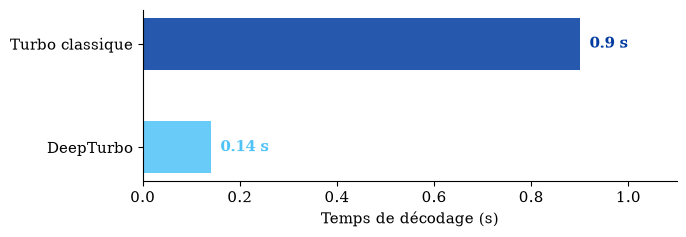

In [58]:
plt.rcParams.update({'font.family': 'serif', 'font.size': 11})

fig, ax = plt.subplots(figsize=(7, 2.5))

methods = ['DeepTurbo', 'Turbo classique']
times = [0.14, 0.90]
colors = ['#4FC3F7', '#003B9F']

bars = ax.barh(methods, times, height=0.5, color=colors, alpha=0.85)

for bar, val, col in zip(bars, times, colors):
    ax.text(val + 0.02, bar.get_y() + bar.get_height()/2, f'{val} s', va='center', fontsize=11, fontweight='bold', color=col)

ax.set_xlabel('Temps de décodage (s)')
ax.set_xlim(0, 1.1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
#plt.savefig('vitesse.png', dpi=300, bbox_inches='tight')
plt.show()